In [ ]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv()
print("Environment variables loaded successfully.")
print(os.environ.get("OPENROUTER_API_KEY"))
print(os.environ.get("LANGSMITH_API_KEY"))
print(os.environ.get("GOOGLE_API_KEY"))

In [5]:
llm_model_google = ChatGoogleGenerativeAI(model="gemini-3.8-flash")
llm_model_openrouter = ChatOpenAI(
     api_key=os.environ.get("OPENROUTER_API_KEY"),
        base_url="https://openrouter.ai/api/v1",
        model="nvidia/nemotron-3.5-lightning:free"
)

In [6]:
llm_model_openrouter.invoke("Capital of France?")

AIMessage(content='The capital of France is Paris.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 106, 'prompt_tokens': 20, 'total_tokens': 126, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 103, 'rejected_prediction_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0, 'cache_write_tokens': 0, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nvidia/nemotron-3.5-lightning:free', 'system_fingerprint': None, 'id': 'gen-1790967507-0P1VyPgDzLpDcwZPoQMA', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a0fdfb-6781-71b2-9d9e-c94c9d41ad47-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 20, 'output_tokens': 106, 'total_tokens': 126, 'input_

In [8]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str

In [ ]:
def generate_outline(state: BlogState) -> BlogState:
    prompt = f"Generate a detailed outline for a blog post titled '{state['title']}'."
    response = llm_model_openrouter.invoke(prompt)
    state['outline'] = response.content
    return state

In [ ]:
def generate_content(state: BlogState) -> BlogState:
    prompt = f"Write a blog post based on the following outline:\n{state['outline']}"
    response = llm_model_openrouter.invoke(prompt)
    state['content'] = response.content
    return state

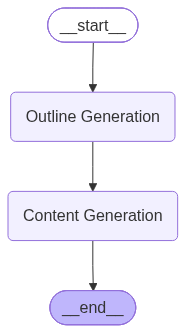

In [11]:
graph = StateGraph(BlogState)
graph.add_node('Outline Generation', generate_outline)
graph.add_node('Content Generation', generate_content)

graph.add_edge(START, 'Outline Generation')
graph.add_edge('Outline Generation', 'Content Generation')
graph.add_edge('Content Generation', END)

workflow = graph.compile()
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [ ]:
initial_state = {'title': 'The Future of AI'}
workflow.invoke(initial_state)